# LangChain vs LangGraph

A conceptual walkthrough: what each framework does, why LangGraph exists, and how the two fit together.

**Contents**

1. [What is LangChain?](#1-what-is-langchain)
2. [Where does the problem come from?](#2-where-does-the-problem-come-from)
3. [Why was LangGraph created?](#3-why-was-langgraph-created)
4. [What exactly is LangGraph?](#4-what-exactly-is-langgraph)
5. [LangChain vs LangGraph](#5-langchain-vs-langgraph)
6. [What LangGraph adds](#6-what-langgraph-adds)
7. [The one-line difference](#7-the-one-line-difference)

<!-- ===== NEW MARKDOWN CELL ===== -->

## 1. What is LangChain?

LangChain is a framework for building applications **around** LLMs. It gives you the building blocks rather than the orchestration.

| Building block | Purpose |
| --- | --- |
| LLM calls | Talk to a model through a common interface |
| Prompt templates | Parameterise and reuse prompts |
| Structured output | Force responses into a schema |
| Tool calling | Let the model invoke functions |
| Retrievers / RAG | Fetch relevant context at query time |
| Document loaders | Read files, web pages, databases |
| Agents | Let the model choose the next step |
| Memory | Carry context across turns |
| Chains | Compose the above in sequence |

The classic shape it handles well is linear:

```text
User Question
      |
      v
     LLM
      |
      v
   Answer
```

For that flow, LangChain on its own is a good fit.

<!-- ===== NEW MARKDOWN CELL ===== -->

## 2. Where does the problem come from?

Now suppose you're building an AI customer-support agent. The flow stops being a straight line:

```text
User asks question
        |
        v
AI analyses question
        |
        v
  Does it need the database?
     /                \
   YES                 NO
    |                   |
    v                   v
 Query DB            Answer
    |
    v
Analyse result
    |
    v
 Need human approval?
     /          \
   YES           NO
    |             |
    v             v
 Human        Continue
approval
    |
    v
Generate answer
    |
    v
 Send response
```

That single diagram introduces:

- branching
- loops
- shared state
- multiple steps
- tool calls
- human approval
- retries
- persistence
- potentially long-running execution

Once all of these are in play, thinking purely in terms of a *chain* becomes awkward.

<!-- ===== NEW MARKDOWN CELL ===== -->

## 3. Why was LangGraph created?

The key insight:

> LLM applications are not always linear chains.

A chain looks like this:

```text
A --> B --> C --> D
```

But a real agent looks more like this:

```text
        +---> Tool A ---+
        |               v
Start --> Agent --> Decision --> Agent
        |               ^
        +---> Tool B ---+
```

Which means you need first-class support for:

- loops
- branches
- cycles
- state changes
- interruptions
- human-in-the-loop

LangGraph exists to model these workflows **as a graph**.

<!-- ===== NEW MARKDOWN CELL ===== -->

## 4. What exactly is LangGraph?

> A framework for building stateful, multi-step, cyclic AI workflows and agents.

The name says it: **Lang + Graph**. You define three things.

### Nodes

A node performs an operation:

```text
call_llm
search_database
call_weather_api
human_approval
```

### Edges

Edges determine where execution goes next:

```text
A --> B
B --> C
C --> A
```

### State

State is the data shared between nodes:

```python
state = {
    "user_question": "...",
    "search_results": [],
    "answer": "",
    "approved": False,
}
```

Put together, a workflow looks like this:

```text
                 +--------------+
                 |              v
User --> Analyse --> Search --> Generate --> Check
                 ^                       |
                 +-------- Retry --------+
```

That's a graph.

<!-- ===== NEW MARKDOWN CELL ===== -->

## 5. LangChain vs LangGraph

| | LangChain | LangGraph |
| --- | --- | --- |
| **Purpose** | Framework for LLM application building | Framework for stateful agent/workflow orchestration |
| **Provides** | LLM building blocks | Graph-based execution |
| **Primitives** | Chains, prompts, tools, retrievers | Nodes, edges, state |
| **Best for** | Straightforward workflows | Complex workflows |
| **Learning curve** | Usually easier to start with | More control over execution |
| **Shape** | Can be linear | Naturally supports branching and loops |
| **Focus** | Components | Workflow / orchestration |

**They are not competitors** — this is the important point:

- **LangChain** = components
- **LangGraph** = orchestration of those components into stateful workflows

<!-- ===== NEW MARKDOWN CELL ===== -->

## 6. What LangGraph adds

### 6.1 Cycles

```text
A --> B --> C --> A
```

Essential for agent loops.

### 6.2 Conditional routing

```text
                 +--> Tool
Agent --> Check --+
                 +--> Answer
```

### 6.3 State management

```python
state = {
    "messages": [],
    "results": [],
    "user_data": {},
    # ...
}
```

### 6.4 Human-in-the-loop

Execution can be paused mid-flow:

```text
Agent
  |
  v
Sensitive action
  |
  v
[ PAUSE ]
  |
  v
Human approval
  |
  v
Continue
```

### 6.5 Persistence

Workflow state can be preserved so an agent resumes later:

```text
Monday                Tuesday
  Agent                 |
    |                   v
    v                Continue
 Research               |
    |                   v
    v              Generate report
[ paused ] ------------>
```

### 6.6 Retry / error handling

```text
Tool
  |
  v
Failed
  |
  v
Retry
  |
  v
Failed
  |
  v
Fallback
```

Modelling this explicitly is far easier in a graph than in a chain.

<!-- ===== NEW MARKDOWN CELL ===== -->

## 7. The one-line difference

> **LangChain** provides components for building LLM applications, while **LangGraph** provides graph-based orchestration for building stateful, cyclic, and controllable agent workflows.

In [1]:
from typing import Annotated  # Annotated allows you to attach extra information/metadata to a type.
from typing_extensions import TypedDict

from langgraph.graph import StateGraph,START,END 

# START and END are not regular nodes.
# They are special graph markers / entry and exit points provided by LangGraph.

from langgraph.graph.message import add_messages # add_messages is a built-in reducer that handles appending messages in the messages state.

# Reducer `LangGraph`

Tells LangGraph how to update a piece of **State** when a node returns new data.

```text
Old state + New data
         |
         v
      Reducer
         |
         v
   Updated state
```

**Example:** `add_messages`

```text
[A, B] + [C]  -->  [A, B, C]
```

| Without a reducer | With `add_messages` |
| --- | --- |
| New value replaces the existing one. | Existing messages are merged with the new ones. |




---

> **Why TypedDict for state?**
>
> State is naturally a dictionary of key-value pairs — nodes conventionally return dictionaries.


In [16]:
from groq import Groq

client = Groq()
models=client.models.list()

for model in models.data:
    print(model.id)

canopylabs/orpheus-v1-english
meta-llama/llama-prompt-guard-2-86m
openai/gpt-oss-20b
whisper-large-v3-turbo
qwen/qwen3.6-27b
openai/gpt-oss-safeguard-20b
whisper-large-v3
canopylabs/orpheus-arabic-saudi
allam-2-7b
groq/compound-mini
groq/compound
qwen/qwen3.8-27b
openai/gpt-oss-120b
meta-llama/llama-prompt-guard-2-22m


In [39]:
from dotenv import load_dotenv
load_dotenv()


from langchain.chat_models import init_chat_model
llm = init_chat_model("groq:openai/gpt-oss-20b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.5.4', 'langchain': '1.3.15'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001F9258A1480>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001F9258B4180>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [18]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages:Annotated[list,add_messages]

# "State is a dictionary, and it has a key called messages whose value is a list. When that list is updated, use add_messages to merge the messages."

In [42]:
type(State)

typing_extensions._TypedDictMeta

In [20]:
# Creation of Node
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

In [43]:
graph_builder=StateGraph(State) # Create a graph using the State structure

graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_node("llmchatbot",chatbot)
graph_builder.add_edge("llmchatbot",END)

graph=graph_builder.compile() # Compile the graph into an executable graph

In [44]:
print(graph)

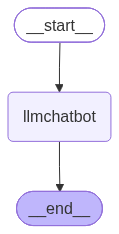

In [45]:
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [31]:
response=graph.invoke({"messages":["Hi"]})
print(response)

{'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='c09a4c9f-5bcf-42b5-8c69-1c6e48a45f25'), AIMessage(content='Hello! 👋 How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "Hi". We need to respond in a friendly manner. The user hasn\'t asked a question. The system instructions say we are ChatGPT, respond accordingly. We can greet back.'}, response_metadata={'token_usage': {'completion_tokens': 60, 'prompt_tokens': 72, 'total_tokens': 132, 'completion_time': 0.060848464, 'completion_tokens_details': {'reasoning_tokens': 40}, 'prompt_time': 0.004241551, 'prompt_tokens_details': None, 'queue_time': 0.310694685, 'total_time': 0.065090015}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_4a35f7bd1b', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a08c27-3695-7482-bdbc-fb6dd086d8bc-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_

In [30]:
response["messages"][-1].content

'Hello! How can I help you today?'

In [38]:
for event in graph.stream({"messages":"how are you?"}): 
    print(event)
    for value in event.values():
        print(value["messages"][-1].content)

# invoke() Waits for the graph to finish and gives you the final result
# stream() Gives you results as each graph step/node executes

{'llmchatbot': {'messages': [AIMessage(content='I’m doing great—thanks for asking! How about you?', additional_kwargs={'reasoning_content': 'User says "how are you?" We need to respond as ChatGPT. It\'s a casual greeting. We can respond politely. The system says we should comply with content policy. It\'s a normal conversation. So we can answer.'}, response_metadata={'token_usage': {'completion_tokens': 68, 'prompt_tokens': 75, 'total_tokens': 143, 'completion_time': 0.072448838, 'completion_tokens_details': {'reasoning_tokens': 46}, 'prompt_time': 0.003564557, 'prompt_tokens_details': None, 'queue_time': 0.301332749, 'total_time': 0.076013395}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_9340e7d14d', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a08c2d-7b84-79c0-a481-fbd36daca586-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 75, 'output_tokens': 68, 'total_tokens': 143, 'ou